In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("E:\\Healthcare & Patient Analytics\\Excel\\Healthcare_Patient_Analytics_Dataset.csv")
df.head()

,PatientID,PatientName,Age,Gender,AdmissionType,Diagnosis,DoctorName,HospitalRoomType,BillAmount_INR,StayDuration_Days
0,PT0001,Kabir Malhotra 15,4,Female,Emergency,Diabetes,Dr. Priya Sharma,Semi-Private,138696,4
1,PT0002,Neha Kapoor 70,12,Female,Emergency,Heart Disease,Dr. Satnam Singh,ICU,414951,12
2,PT0003,Aanya Mishra 4,72,Male,Elective,Trauma,Dr. Kiran Patel,ICU,458944,19
3,PT0004,Ishaan Nair 1,21,Female,Urgent,Infection,Dr. Priya Sharma,ICU,203587,15
4,PT0005,Aditya Verma 49,13,Female,Urgent,Trauma,Dr. Aman Verma,ICU,431137,19


In [4]:
df.isnull().sum()


PatientID            0
PatientName          0
Age                  0
Gender               0
AdmissionType        0
Diagnosis            0
DoctorName           0
HospitalRoomType     0
BillAmount_INR       0
StayDuration_Days    0
dtype: int64

In [5]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2095    False
2096    False
2097    False
2098    False
2099    False
Length: 2100, dtype: bool

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   PatientID          2100 non-null   str  
 1   PatientName        2100 non-null   str  
 2   Age                2100 non-null   int64
 3   Gender             2100 non-null   str  
 4   AdmissionType      2100 non-null   str  
 5   Diagnosis          2100 non-null   str  
 6   DoctorName         2100 non-null   str  
 7   HospitalRoomType   2100 non-null   str  
 8   BillAmount_INR     2100 non-null   int64
 9   StayDuration_Days  2100 non-null   int64
dtypes: int64(3), str(7)
memory usage: 164.2 KB


In [7]:
print(df.shape)

(2100, 10)


In [8]:
df.head()

,PatientID,PatientName,Age,Gender,AdmissionType,Diagnosis,DoctorName,HospitalRoomType,BillAmount_INR,StayDuration_Days
0,PT0001,Kabir Malhotra 15,4,Female,Emergency,Diabetes,Dr. Priya Sharma,Semi-Private,138696,4
1,PT0002,Neha Kapoor 70,12,Female,Emergency,Heart Disease,Dr. Satnam Singh,ICU,414951,12
2,PT0003,Aanya Mishra 4,72,Male,Elective,Trauma,Dr. Kiran Patel,ICU,458944,19
3,PT0004,Ishaan Nair 1,21,Female,Urgent,Infection,Dr. Priya Sharma,ICU,203587,15
4,PT0005,Aditya Verma 49,13,Female,Urgent,Trauma,Dr. Aman Verma,ICU,431137,19


In [9]:
df=df.rename(columns={"BillAmount_INR":"Bill Amount","StayDuration_Days":"Stay Days","HospitalRoomType":"Room Type"})
df.head()

,PatientID,PatientName,Age,Gender,AdmissionType,Diagnosis,DoctorName,Room Type,Bill Amount,Stay Days
0,PT0001,Kabir Malhotra 15,4,Female,Emergency,Diabetes,Dr. Priya Sharma,Semi-Private,138696,4
1,PT0002,Neha Kapoor 70,12,Female,Emergency,Heart Disease,Dr. Satnam Singh,ICU,414951,12
2,PT0003,Aanya Mishra 4,72,Male,Elective,Trauma,Dr. Kiran Patel,ICU,458944,19
3,PT0004,Ishaan Nair 1,21,Female,Urgent,Infection,Dr. Priya Sharma,ICU,203587,15
4,PT0005,Aditya Verma 49,13,Female,Urgent,Trauma,Dr. Aman Verma,ICU,431137,19


In [10]:
df["Per day cost"]=round(df["Bill Amount"]/df["Stay Days"],2)
df.head()

,PatientID,PatientName,Age,Gender,AdmissionType,Diagnosis,DoctorName,Room Type,Bill Amount,Stay Days,Per day cost
0,PT0001,Kabir Malhotra 15,4,Female,Emergency,Diabetes,Dr. Priya Sharma,Semi-Private,138696,4,34674.00
1,PT0002,Neha Kapoor 70,12,Female,Emergency,Heart Disease,Dr. Satnam Singh,ICU,414951,12,34579.25
2,PT0003,Aanya Mishra 4,72,Male,Elective,Trauma,Dr. Kiran Patel,ICU,458944,19,24154.95
3,PT0004,Ishaan Nair 1,21,Female,Urgent,Infection,Dr. Priya Sharma,ICU,203587,15,13572.47
4,PT0005,Aditya Verma 49,13,Female,Urgent,Trauma,Dr. Aman Verma,ICU,431137,19,22691.42


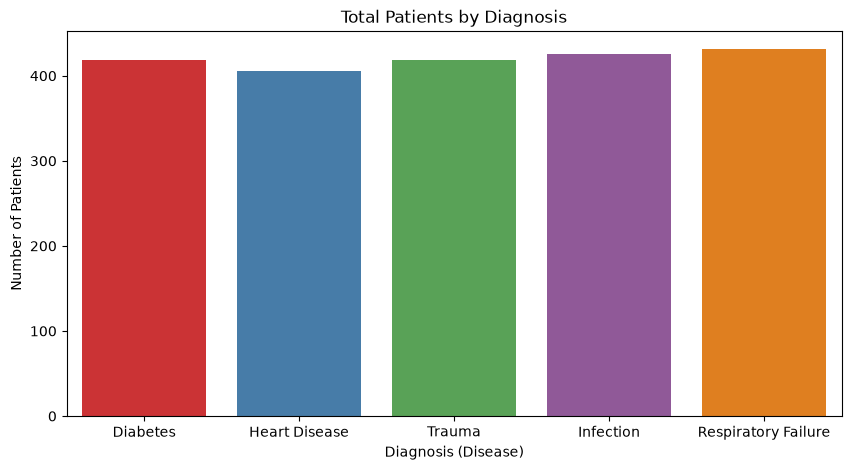

In [11]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Diagnosis", palette="Set1", hue="Diagnosis", legend=False)

plt.title("Total Patients by Diagnosis", )
plt.xlabel("Diagnosis (Disease)")
plt.ylabel("Number of Patients")
plt.show()

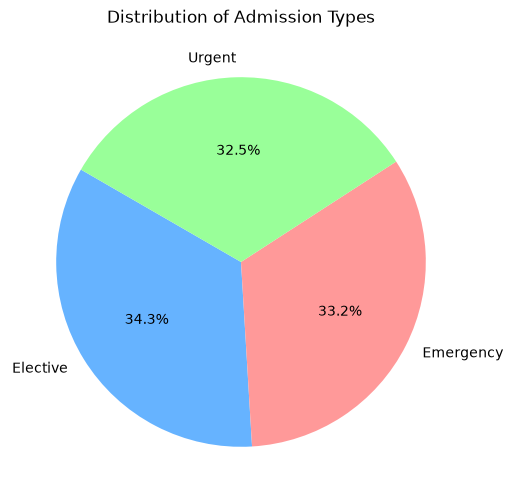

In [12]:
admission_counts= df["AdmissionType"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(admission_counts, labels=admission_counts.index, autopct="%1.1f%%", startangle=150, colors=["#66b3ff","#ff9999","#99ff99"])
plt.title("Distribution of Admission Types")
plt.show()

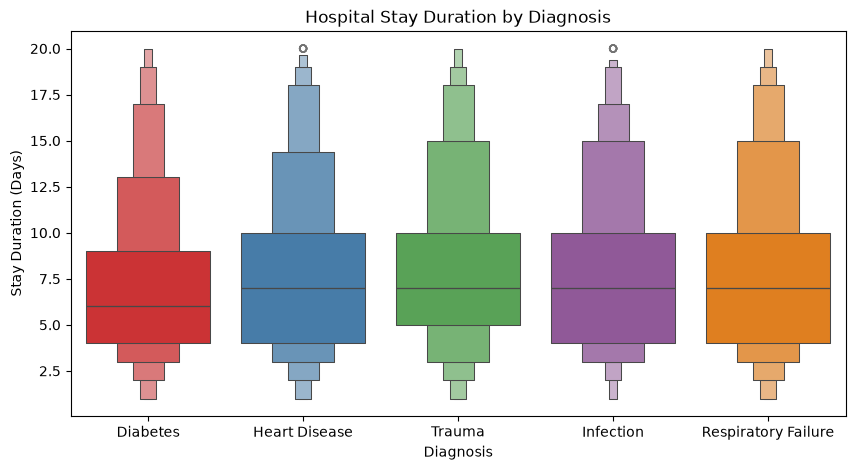

In [35]:
plt.figure(figsize=(10,5))
sns.boxenplot(data=df, x="Diagnosis", y="Stay Days", palette="Set1", hue="Diagnosis", legend=False)

plt.title("Hospital Stay Duration by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Stay Duration (Days)")
plt.show()

In [ ]:
from sqlalchemy import create_engine
username = "root" 
password = " "
host = "localhost"
port = 3306
database_name = "Healthcare_Analytics_DB" 

engine = create_engine(f"mysql+pymysql://{"root"}:{"  "}@{"localhost"}:{3306}/{"Healthcare_Analytics_DB"}")
df.to_sql(name="patient_data", con=engine, if_exists="replace", index=False)
print("data transfer")

data transfer
